### Gini impurity :- 
Gini Impurity measures how mixed the classes are within a node of a Decision Tree.

In [1]:
def gini_impurity(labels):
    total = len(labels)

    if total == 0:
        return 0.0

    gini = 1.0

    for label in set(labels):
        probability = labels.count(label) / total
        gini -= probability ** 2

    return gini


print(gini_impurity(["Pass"] * 10))
print(gini_impurity(["Pass"] * 5 + ["Fail"] * 5))
print(gini_impurity(["Pass"] * 8 + ["Fail"] * 2))

0.0
0.5
0.31999999999999984


In [4]:
# entropy
import math

def entropy(labels):
    total = len(labels)

    if total == 0:
        return 0

    entropy_value = 0

    for label in set(labels):
        probability = labels.count(label) / total
        entropy_value -= probability * math.log2(probability)

    return entropy_value


# Example 1: Completely pure dataset
data1 = ["Pass", "Pass", "Pass", "Pass"]
print("Entropy 1:", entropy(data1))

# Example 2: Equally distributed classes
data2 = ["Pass", "Pass", "Fail", "Fail"]
print("Entropy 2:", entropy(data2))

# Example 3: Unequal distribution
data3 = ["Pass", "Pass", "Pass", "Fail"]
print("Entropy 3:", entropy(data3))

Entropy 1: 0.0
Entropy 2: 1.0
Entropy 3: 0.8112781244591328


In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load dataset
iris = load_iris()
X, y = iris.data, iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create a controlled Decision Tree
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
print("Training Accuracy:", model.score(X_train, y_train))
print("Testing Accuracy:", accuracy_score(y_test, y_pred))

Training Accuracy: 0.9833333333333333
Testing Accuracy: 0.9666666666666667


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

In [6]:
# Load dataset
data = load_breast_cancer()

# Convert features into a DataFrame
X = pd.DataFrame(data.data, columns=data.feature_names)

# Target variable
y = pd.Series(data.target, name="target")

print("Dataset shape:", X.shape)
print("\nFirst 5 rows:")
print(X.head())

print("\nTarget classes:")
print(data.target_names)

print("\nClass distribution:")
print(y.value_counts())

Dataset shape: (569, 30)

First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst 

Missing values: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null   

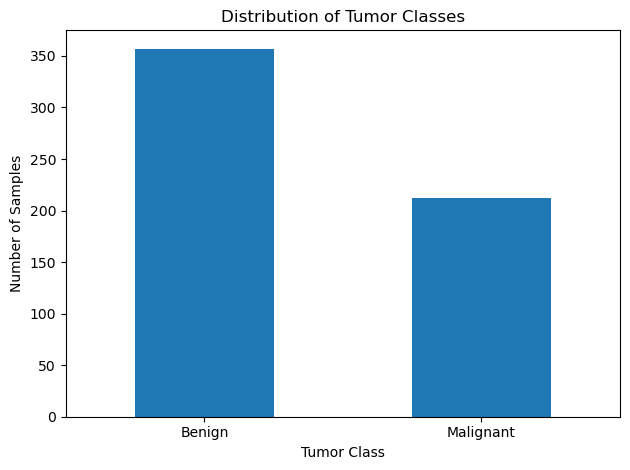

In [7]:
# Check missing values
print("Missing values:", X.isnull().sum().sum())

# Dataset information
print("\nDataset information:")
print(X.info())

# Target distribution
print("\nTarget distribution:")
print(y.value_counts())

# Visualize class distribution
y.map({0: "Malignant", 1: "Benign"}).value_counts().plot(
    kind="bar",
    title="Distribution of Tumor Classes",
    xlabel="Tumor Class",
    ylabel="Number of Samples"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [9]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [10]:
y_pred = model.predict(X_test)

print("First 10 actual labels:")
print(y_test.iloc[:10].to_list())

print("\nFirst 10 predictions:")
print(y_pred[:10])

First 10 actual labels:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 0]

First 10 predictions:
[0 1 0 1 0 1 1 0 0 0]


In [11]:
train_accuracy = accuracy_score(y_train, model.predict(X_train))
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy:  {test_accuracy:.4f}")

Training Accuracy: 0.9758
Testing Accuracy:  0.9211


In [12]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names,
        digits=4
    )
)

              precision    recall  f1-score   support

   malignant     0.8837    0.9048    0.8941        42
      benign     0.9437    0.9306    0.9371        72

    accuracy                         0.9211       114
   macro avg     0.9137    0.9177    0.9156       114
weighted avg     0.9216    0.9211    0.9212       114



Confusion Matrix:
[[38  4]
 [ 5 67]]


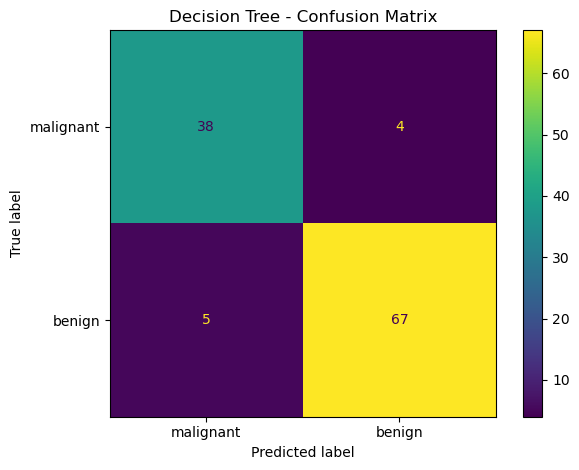

In [13]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

display.plot()
plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()


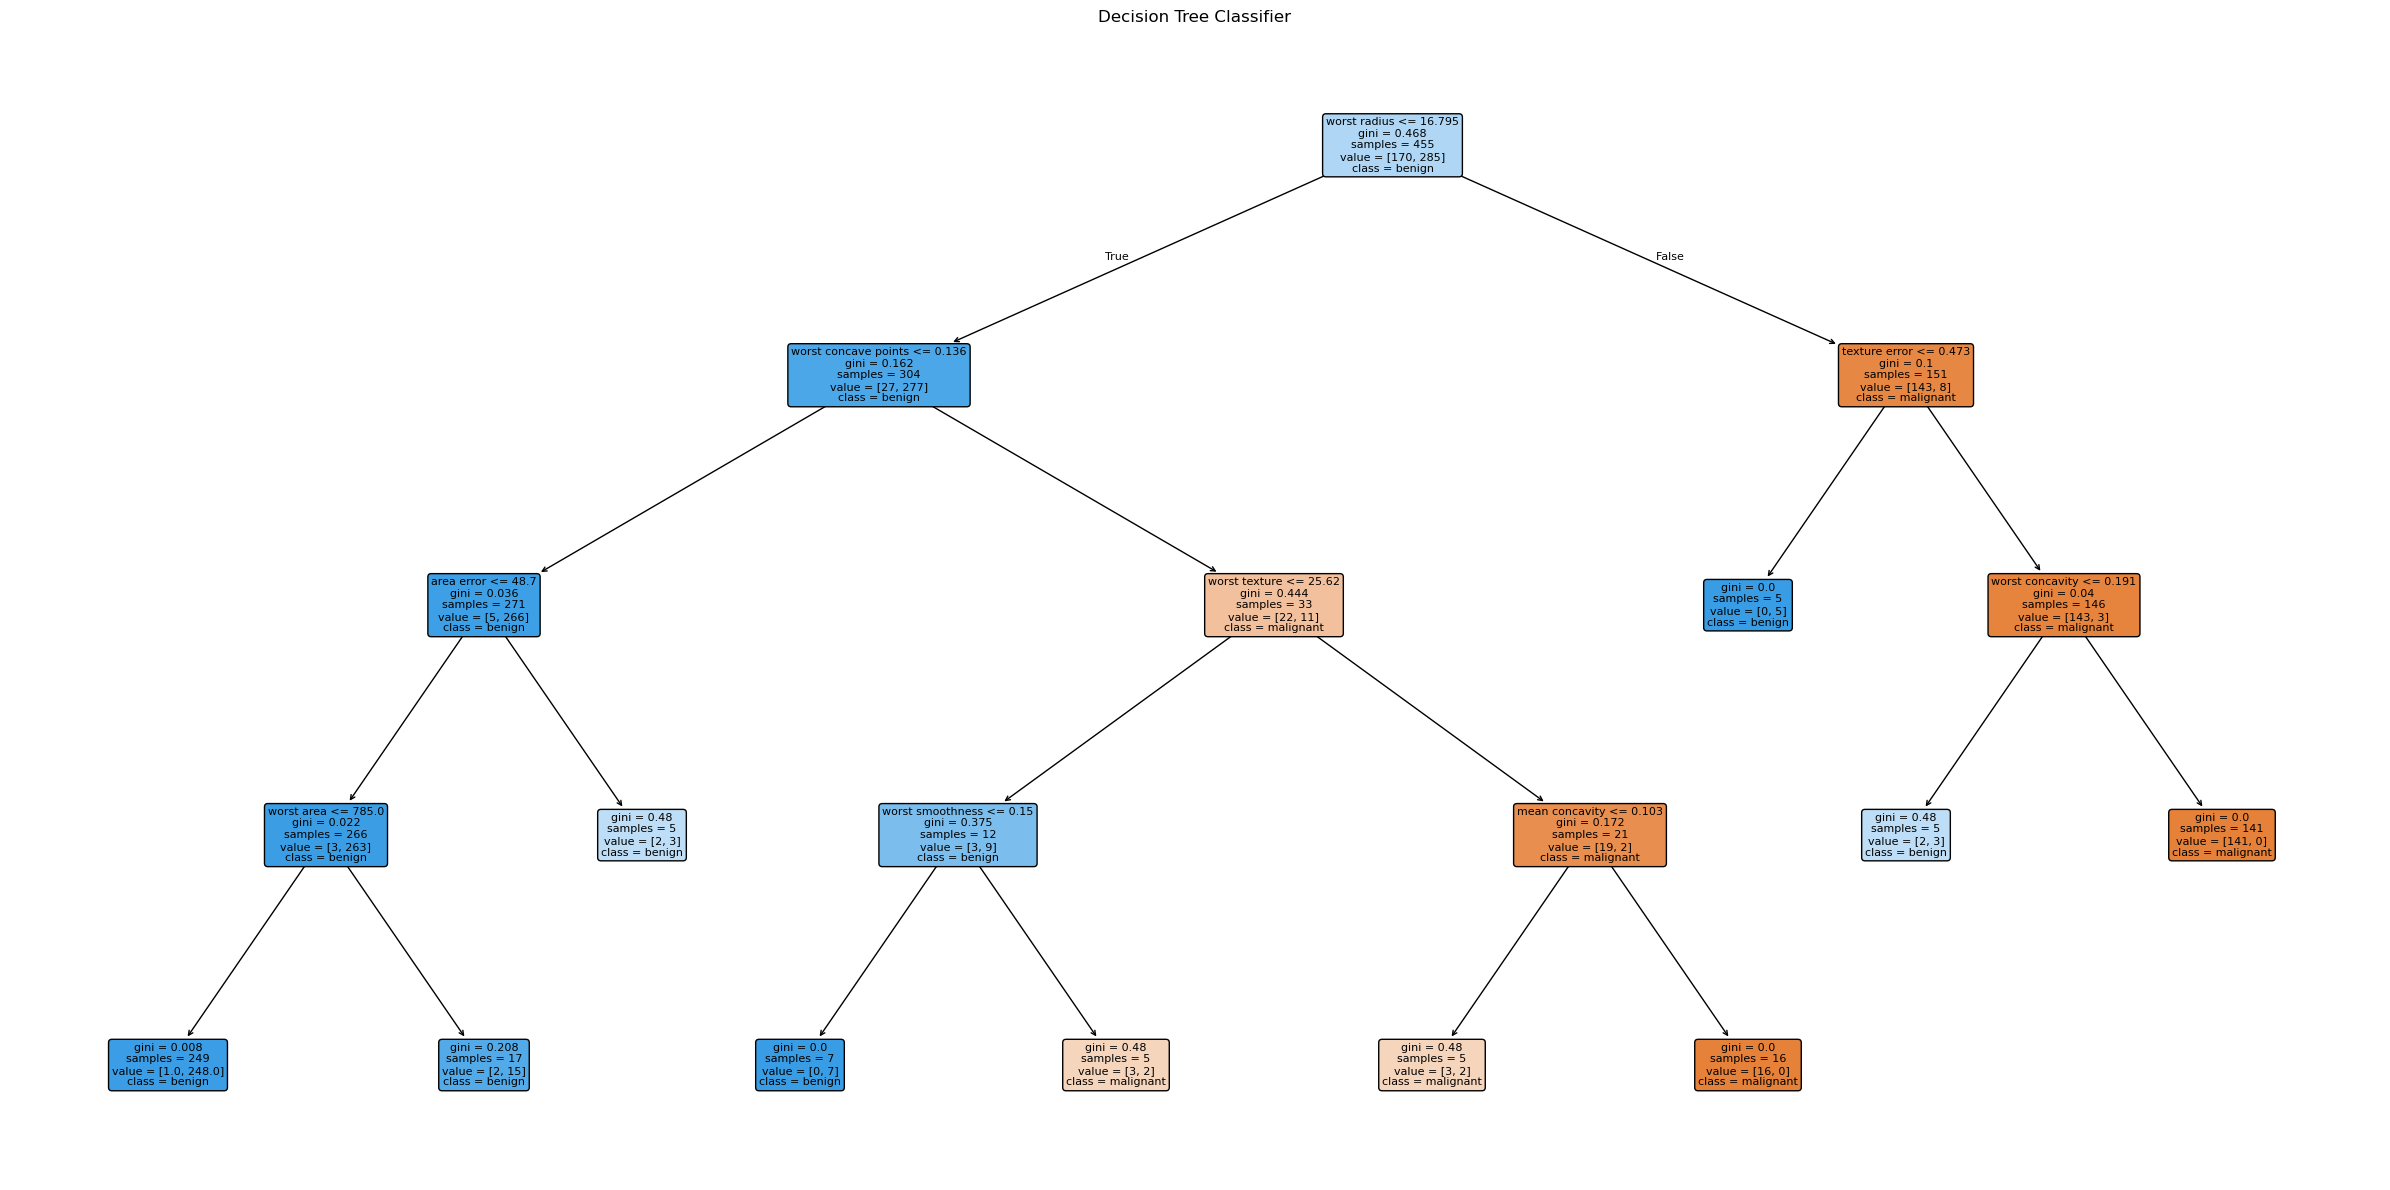

In [14]:
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier")
plt.tight_layout()
plt.show()

                 Feature  Importance
20          worst radius    0.751145
27  worst concave points    0.124955
11         texture error    0.046883
21         worst texture    0.033095
26       worst concavity    0.017573
24      worst smoothness    0.010614
13            area error    0.007497
6         mean concavity    0.006162
23            worst area    0.002077
0            mean radius    0.000000


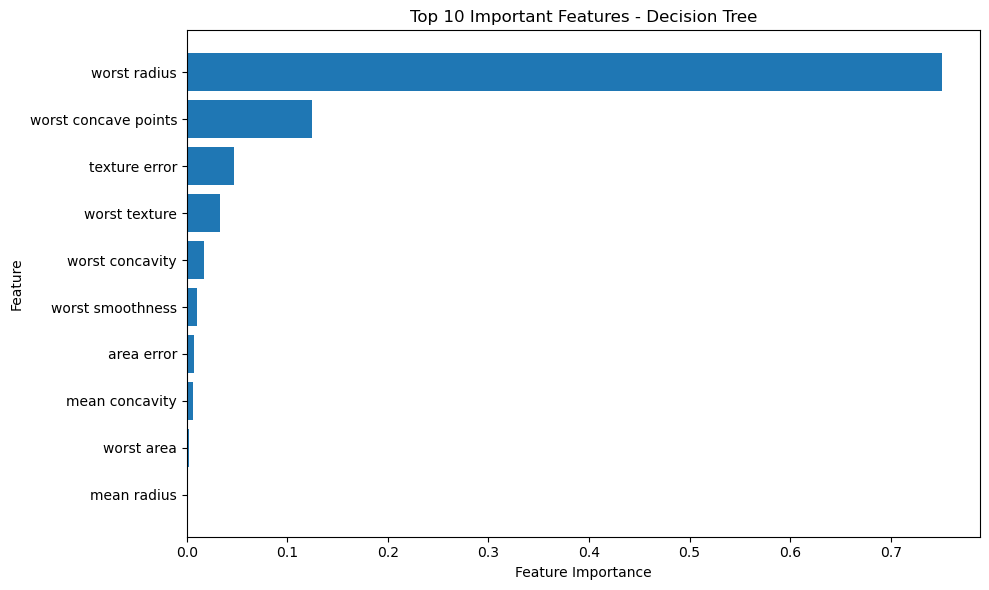

In [15]:
feature_importance = pd.DataFrame({
    "Feature": data.feature_names,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(10))

# Visualize the top 10 features
top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features - Decision Tree")
plt.tight_layout()
plt.show()

In [16]:
param_grid = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [3, 4, 5, 6, 8, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "ccp_alpha": [0.0, 0.001, 0.01]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(f"{grid_search.best_score_:.4f}")

# Best estimator is already refitted on the full training set
best_model = grid_search.best_estimator_

# Evaluate once on the held-out test set
best_predictions = best_model.predict(X_test)

print("\nTest Accuracy:")
print(f"{accuracy_score(y_test, best_predictions):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        target_names=data.target_names,
        digits=4
    )
)

Best Parameters:
{'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best Cross-Validation Accuracy:
0.9385

Test Accuracy:
0.9386

Classification Report:
              precision    recall  f1-score   support

   malignant     0.9070    0.9286    0.9176        42
      benign     0.9577    0.9444    0.9510        72

    accuracy                         0.9386       114
   macro avg     0.9324    0.9365    0.9343       114
weighted avg     0.9390    0.9386    0.9387       114



In [17]:
# Probability of class 1 (benign)
y_prob = best_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print(f"ROC-AUC Score: {auc:.4f}")

ROC-AUC Score: 0.9342


In [18]:
# Use one test sample as an example
sample = X_test.iloc[[0]]

prediction = best_model.predict(sample)[0]
probabilities = best_model.predict_proba(sample)[0]

predicted_class = data.target_names[prediction]

print("Predicted Class:", predicted_class)
print("Probability of Malignant:", probabilities[0])
print("Probability of Benign:", probabilities[1])

Predicted Class: malignant
Probability of Malignant: 1.0
Probability of Benign: 0.0


Exception ignored in: <function ResourceTracker.__del__ at 0x106d69bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x107175bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106d69bc0>
Traceback (most recent call last